In [1]:
import tensorflow as tf

In [ ]:
#RESIZING all images to imagesize.which is useful for better model training and speedup it.
imagesize=(224,224)
batchsize=32#instead of passing all images at once to model,passing the images in batches.

In [ ]:
#tensorflow function used to get the images from the directory.
#here seed is used to avois the getting different images each time you load this cell.
#Shuffle is used to interchange the files(images) in the directory.
train_ds=tf.keras.utils.image_dataset_from_directory(
    "C:\\Users\\munir\\OneDrive\\Pictures\\CNN\\train",
    image_size=imagesize,batch_size=batchsize,shuffle=True,validation_split=0.2,subset="training",seed=42
)
val_ds=tf.keras.utils.image_dataset_from_directory(
    "C:\\Users\\munir\\OneDrive\\Pictures\\CNN\\train",
    seed=42,validation_split=0.2,subset="validation",image_size=imagesize,batch_size=batchsize
)

Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.


In [94]:
test_ds=tf.keras.utils.image_dataset_from_directory(
    "C:\\Users\\munir\\OneDrive\\Pictures\\CNN\\test",
    image_size=imagesize,batch_size=batchsize,shuffle=False
)

Found 1000 files belonging to 4 classes.


In [95]:
print(train_ds.class_names)

['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [96]:
for i,l in train_ds.take(1):
    print(i.shape)
    print(l.shape)

(32, 224, 224, 3)
(32,)


In [97]:
len(train_ds),len(test_ds),len(val_ds)

(125, 32, 32)

In [98]:
classes=train_ds.class_names

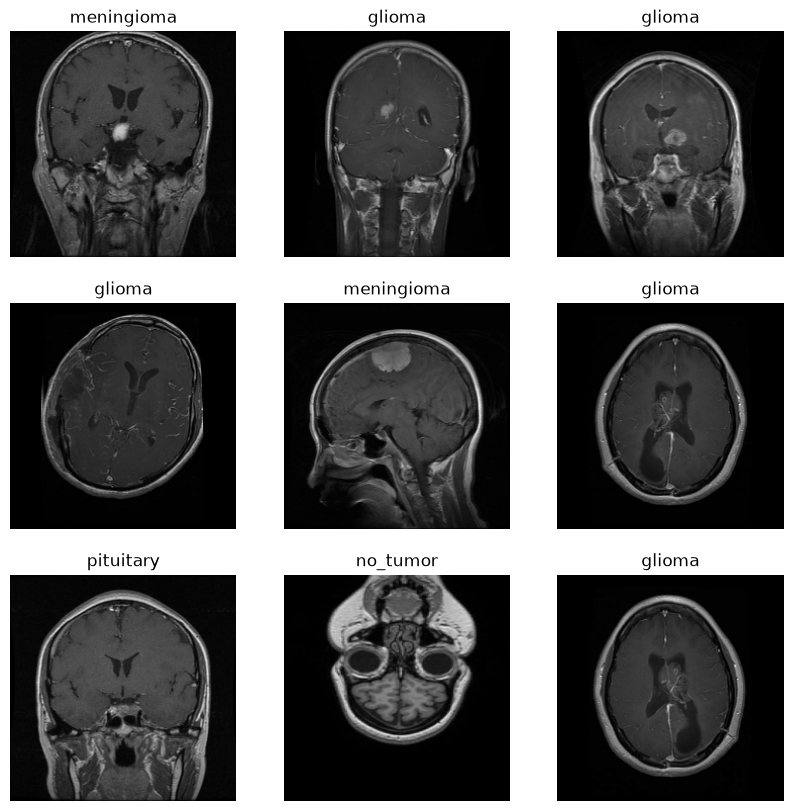

In [ ]:
#vizuallization of the images in the train_ds of batch-1
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
for image,label in train_ds.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype("uint8"))
        plt.title(classes[label[i]])
        plt.axis("off")

In [ ]:
#train_ds = train_ds.map(lambda x, y: (x / 255.0, y))

In [100]:
for image,lables in train_ds.take(1):
    print(image[0])

tf.Tensor(
[[[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]
  ...
  [0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]
  ...
  [0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]
  ...
  [0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]

 ...

 [[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]
  ...
  [0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]
  ...
  [0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]
  ...
  [0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]], shape=(224, 224, 3), dtype=float32)


In [101]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop=EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)

In [103]:
from tensorflow.keras.layers import RandomFlip,RandomRotation,RandomZoom,RandomTranslation
data_augmentation=Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1),
])

In [104]:
for images, labels in train_ds.take(1):
    sample_images = images
    sample_labels = labels

In [105]:
augmented_images = data_augmentation(sample_images)

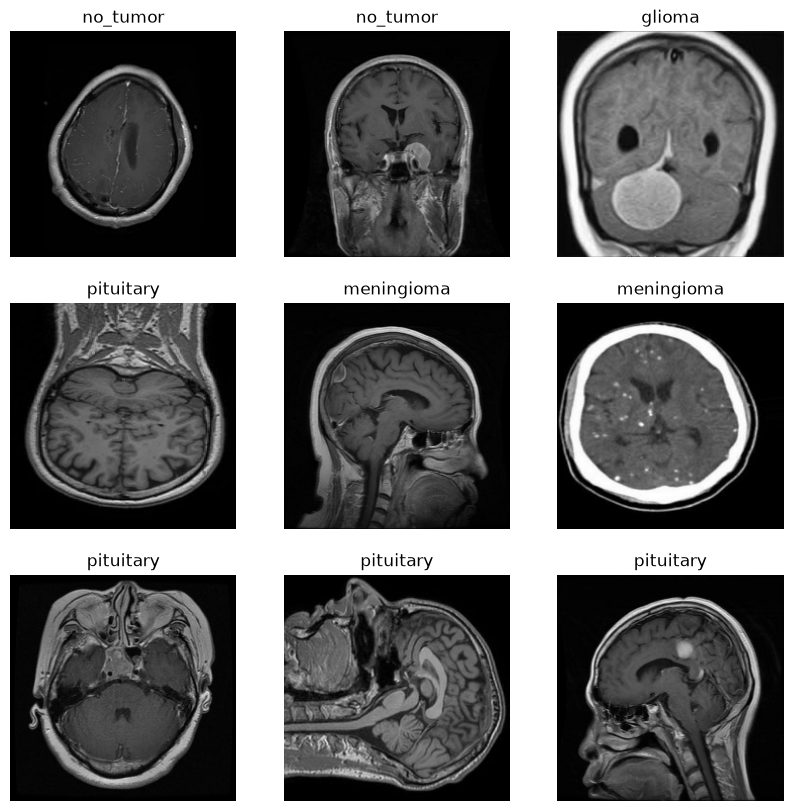

In [106]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images,batches in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(classes[labels[i]])
        plt.axis("off")

    plt.show()

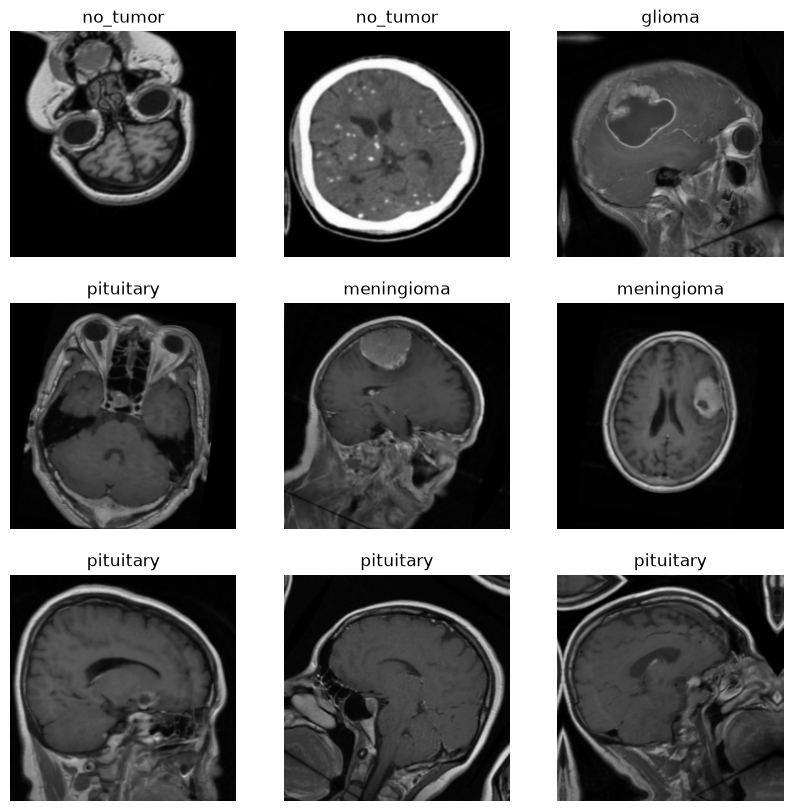

In [107]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(augmented_images[i].numpy().astype("uint8"))

    plt.title(classes[sample_labels[i]])
    plt.axis("off")

plt.show()

In [44]:
from tensorflow.keras.layers import Dense,Flatten,Rescaling,Conv2D,MaxPool2D,Dropout
from tensorflow.keras.models import Sequential
cnn_model=Sequential([
    Rescaling(1./255,input_shape=(224,224,3)),
    Conv2D(filters=32,kernel_size=(3,3),activation="relu"),
    MaxPool2D((3,3)),
    Conv2D(filters=64,kernel_size=(3,3),activation="relu"),
    MaxPool2D((3,3)),
    Flatten(),
    Dense(65,activation="relu"),
    Dense(4,activation="softmax")
])

cnn_model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

his=cnn_model.fit(train_ds,validation_data=val_ds,epochs=10)

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 54s 420ms/step - accuracy: 0.6950 - loss: 0.7750 - val_accuracy: 0.7820 - val_loss: 0.5337
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 50s 397ms/step - accuracy: 0.8708 - loss: 0.3617 - val_accuracy: 0.8890 - val_loss: 0.3107
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 51s 411ms/step - accuracy: 0.9258 - loss: 0.2049 - val_accuracy: 0.8960 - val_loss: 0.3353
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 43s 346ms/step - accuracy: 0.9523 - loss: 0.1302 - val_accuracy: 0.9250 - val_loss: 0.2495
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 43s 345ms/step - accuracy: 0.9797 - loss: 0.0673 - val_accuracy: 0.9190 - val_loss: 0.2694
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 42s 336ms/step - accuracy: 0.9827 - loss: 0.0539 - val_accuracy: 0.9000 - val_loss: 0.3557
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 42s 335ms/step - accuracy: 0.9905 - loss: 0.0347 - val_accuracy: 0.8690 - val_loss: 0.5127
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 44s 350ms/step - accuracy: 0.9815 - loss: 0

In [46]:
his.history

{'accuracy': [0.6949999928474426,
  0.8707500100135803,
  0.9257500171661377,
  0.9522500038146973,
  0.9797499775886536,
  0.9827499985694885,
  0.9904999732971191,
  0.9815000295639038,
  0.9884999990463257,
  0.9944999814033508],
 'loss': [0.7750072479248047,
  0.3617302179336548,
  0.2048514187335968,
  0.1302146166563034,
  0.06733858585357666,
  0.05388125404715538,
  0.034662310034036636,
  0.05548720061779022,
  0.037038177251815796,
  0.023085568100214005],
 'val_accuracy': [0.7820000052452087,
  0.8889999985694885,
  0.8960000276565552,
  0.925000011920929,
  0.9190000295639038,
  0.8999999761581421,
  0.8690000176429749,
  0.9139999747276306,
  0.925000011920929,
  0.8920000195503235],
 'val_loss': [0.53370600938797,
  0.31067004799842834,
  0.3353026807308197,
  0.24954423308372498,
  0.26941680908203125,
  0.3557313084602356,
  0.5127188563346863,
  0.35285186767578125,
  0.2967785596847534,
  0.43589848279953003]}

In [47]:
loss,acc=cnn_model.evaluate(val_ds)
print(f"cnn_acc is {acc} and cnn_loss is {loss}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - accuracy: 0.8920 - loss: 0.4359
cnn_acc is 0.8920000195503235 and cnn_loss is 0.43589848279953003


In [130]:
classes

['glioma', 'meningioma', 'no_tumor', 'pituitary']

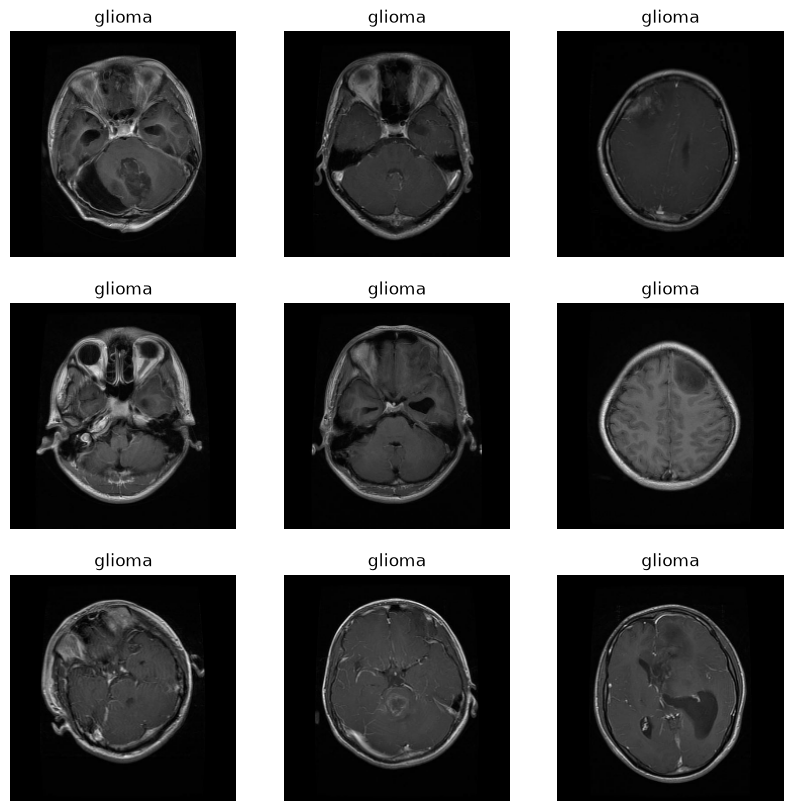

In [50]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
for image,label in test_ds.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype("uint8"))
        plt.title(classes[label[i]])
        plt.axis("off")

In [54]:
import numpy as np
y_prob=cnn_model.predict(test_ds)
y_prob
y_pred=np.argmax(y_prob,axis=1)
y_pred

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step


array([0, 3, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 3,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 2, 1, 0, 0, 3, 3, 0, 0, 0, 0,
       3, 0, 1, 0, 0, 2, 2, 0, 0, 0, 0, 1, 3, 0, 3, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 3, 0, 0, 0, 3, 0, 0, 0,
       3, 0, 0, 0, 1, 0, 0, 1, 3, 0, 0, 0, 0, 0, 1, 0, 3, 0, 0, 3, 3, 3,
       0, 1, 3, 0, 1, 0, 0, 2, 0, 0, 0, 3, 1, 3, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 3, 2, 1,
       1, 2, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1,

In [ ]:
len(test_ds)

38

In [127]:
import numpy as np

y_true = []

for images, labels in test_ds:
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_true

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [131]:
classes=np.array(classes)

In [132]:
import pandas as pd
data=pd.DataFrame({
    "true_labels":classes[y_true],
    "predicted_labels":classes[y_pred]
})

In [136]:
data.head()

,true_labels,predicted_labels
0,glioma,glioma
1,glioma,pituitary
2,glioma,glioma
3,glioma,meningioma
4,glioma,glioma


In [26]:
his.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [61]:
import pandas as pd
data=pd.DataFrame({
    "accuracy":his.history["accuracy"],
    "loss":his.history["loss"],
    "val_loss":his.history["val_loss"],
    "val_acc":his.history["val_accuracy"]
})
data.head()

,accuracy,loss,val_loss,val_acc
0,0.69500,0.775007,0.533706,0.782
1,0.87075,0.361730,0.310670,0.889
2,0.92575,0.204851,0.335303,0.896
3,0.95225,0.130215,0.249544,0.925
4,0.97975,0.067339,0.269417,0.919


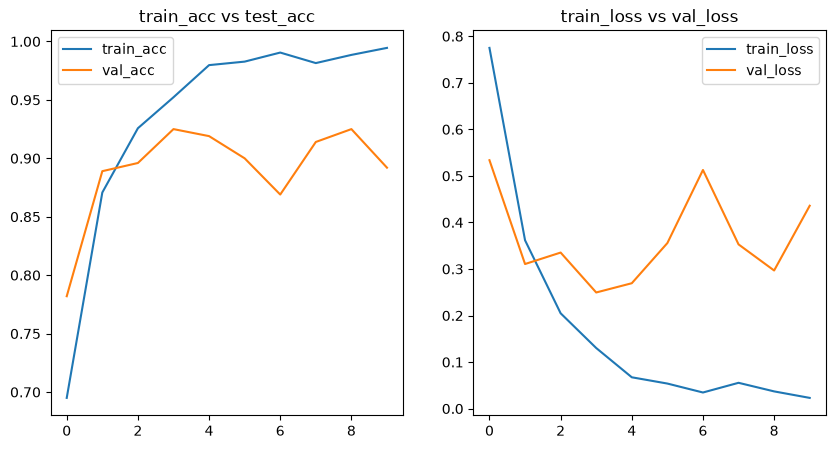

In [62]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(his.history["accuracy"],label="train_acc")
plt.plot(his.history["val_accuracy"],label="val_acc")
plt.title("train_acc vs test_acc")
plt.legend()
plt.subplot(1,2,2)
plt.plot(his.history["loss"],label="train_loss")
plt.plot(his.history["val_loss"],label="val_loss")
plt.title("train_loss vs val_loss")
plt.legend()

acc of the cnn is 0.889.
              precision    recall  f1-score   support

      glioma       0.92      0.81      0.86       254
  meningioma       0.91      0.80      0.85       306
    no_tumor       0.87      0.99      0.93       140
   pituitary       0.86      1.00      0.93       300

    accuracy                           0.89      1000
   macro avg       0.89      0.90      0.89      1000
weighted avg       0.89      0.89      0.89      1000



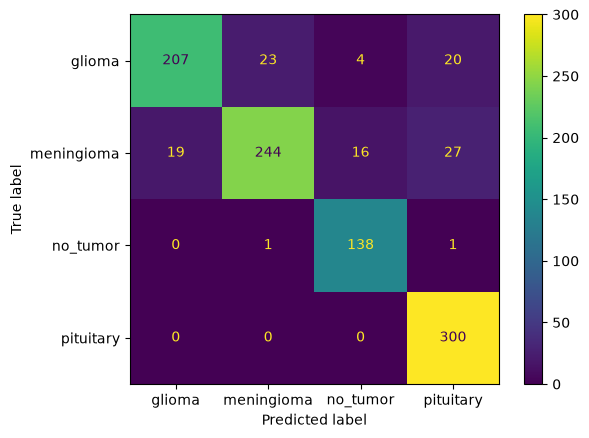

In [64]:
from sklearn.metrics import classification_report,accuracy_score,confusion_matrix,ConfusionMatrixDisplay
acc=accuracy_score(y_true,y_pred)
cm=confusion_matrix(y_true,y_pred)
dis=ConfusionMatrixDisplay(cm,display_labels=classes)

print(f"acc of the cnn is {acc}.")
print(classification_report(y_true,y_pred,target_names=classes))
dis.plot()

In [83]:
cnn_model.save("brain_tumor_pred.keras")

In [85]:
import tensorflow as tf

loaded_model = tf.keras.models.load_model("brain_tumor_pred.keras")

In [86]:
loaded_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 65)             │     2,396,225 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,247,645 (27.65 MB)

 Trainable params: 2,415,881 (9.22 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,831,764 (18.43 MB)

In [87]:
y_prob_loaded = loaded_model.predict(test_ds)

y_pred_loaded = np.argmax(y_prob_loaded, axis=1)

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step


In [88]:
y_pred_loaded[0:10:1]

array([0, 3, 0, 1, 0, 1, 0, 0, 0, 0])

# DATA AUGMENTATION TO AVOID OVERFITTING

In [109]:
cnn_data_aug_model=Sequential([
    data_augmentation,
    Rescaling(1./255,input_shape=(224,224,3)),
    Conv2D(filters=32,kernel_size=(3,3),activation="relu"),
    MaxPool2D((3,3)),
    Conv2D(filters=64,kernel_size=(3,3),activation="relu"),
    MaxPool2D((3,3)),
    Flatten(),
    Dense(65,activation="relu"),
    Dense(4,activation="softmax")
])

cnn_data_aug_model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

cnn_his=cnn_data_aug_model.fit(train_ds,validation_data=val_ds,epochs=10)

Epoch 1/10


c:\Users\munir\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\munir\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 499ms/step - accuracy: 0.5890 - loss: 0.9996 - val_accuracy: 0.7000 - val_loss: 0.6861
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 56s 450ms/step - accuracy: 0.7433 - loss: 0.6593 - val_accuracy: 0.7940 - val_loss: 0.5363
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 56s 445ms/step - accuracy: 0.7855 - loss: 0.5516 - val_accuracy: 0.8250 - val_loss: 0.4620
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 59s 471ms/step - accuracy: 0.8238 - loss: 0.4747 - val_accuracy: 0.8450 - val_loss: 0.3978
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 58s 460ms/step - accuracy: 0.8325 - loss: 0.4362 - val_accuracy: 0.8320 - val_loss: 0.4282
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 71s 564ms/step - accuracy: 0.8485 - loss: 0.4050 - val_accuracy: 0.8600 - val_loss: 0.3687
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 74s 588ms/step - accuracy: 0.8602 - loss: 0.3764 - val_accuracy: 0.8820 - val_loss: 0.3300
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 75s 597ms/step - accuracy: 0.8615 - loss: 0.3566 - val

In [117]:
cnn_his.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [118]:
data_aug_df=pd.DataFrame({
    "accuracy":cnn_his.history["accuracy"],
    "loss":cnn_his.history["loss"],
    "val_acc":cnn_his.history["val_accuracy"],
    "val_loss":cnn_his.history["val_loss"]
})
data_aug_df.head()

,accuracy,loss,val_acc,val_loss
0,0.58900,0.999626,0.700,0.686094
1,0.74325,0.659340,0.794,0.536270
2,0.78550,0.551599,0.825,0.462004
3,0.82375,0.474726,0.845,0.397757
4,0.83250,0.436237,0.832,0.428150


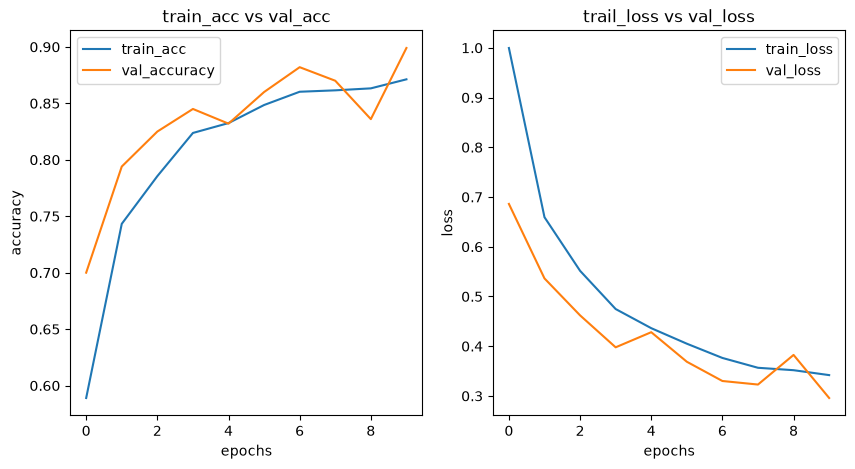

In [123]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(cnn_his.history["accuracy"],label="train_acc")
plt.plot(cnn_his.history["val_accuracy"],label="val_accuracy")
plt.title("train_acc vs val_acc")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.legend()
plt.subplot(1,2,2)
plt.plot(cnn_his.history["loss"],label="train_loss")
plt.plot(cnn_his.history["val_loss"],label="val_loss")
plt.title("trail_loss vs val_loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend()

In [125]:
y_prob_data=cnn_data_aug_model.predict(test_ds)
y_prob_data
y_pred_cnn=np.argmax(y_prob_data,axis=1)
y_pred_cnn

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step


array([3, 3, 0, 3, 0, 1, 0, 0, 0, 3, 3, 1, 0, 3, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 3, 0, 0, 3, 0, 0, 3, 1, 0, 3, 0, 3, 1, 2, 3, 3, 0, 0, 0, 3, 0,
       0, 0, 0, 0, 1, 3, 3, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 3, 3, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 3, 3, 0,
       0, 0, 3, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 3, 3,
       1, 1, 1, 1, 1, 1, 3, 0, 1, 1, 0, 1, 3, 2, 2, 1, 1, 1, 1, 1, 2, 1,
       1, 1, 2, 1, 3, 3, 1, 1, 3, 2, 1, 1, 2, 1, 1, 2, 0, 1, 2, 3, 2, 1,
       1, 1, 1, 1, 3, 1, 1, 1, 2, 1, 2, 2, 1, 2, 3,

In [133]:
cnn_data_aug=pd.DataFrame({
    "true_labels":classes[y_true],
    "predicted_labels":classes[y_pred_cnn]
})

In [134]:
cnn_data_aug.head()

,true_labels,predicted_labels
0,glioma,pituitary
1,glioma,pituitary
2,glioma,glioma
3,glioma,pituitary
4,glioma,glioma


acc of the cnn is 0.889.
              precision    recall  f1-score   support

      glioma       0.92      0.81      0.86       254
  meningioma       0.91      0.80      0.85       306
    no_tumor       0.87      0.99      0.93       140
   pituitary       0.86      1.00      0.93       300

    accuracy                           0.89      1000
   macro avg       0.89      0.90      0.89      1000
weighted avg       0.89      0.89      0.89      1000



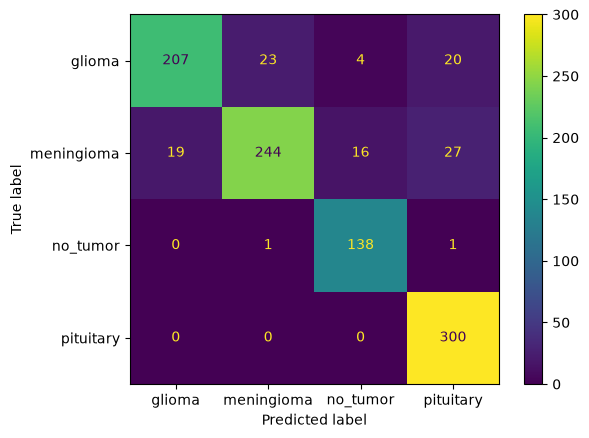

In [135]:
cnn_aug_acc=accuracy_score(y_true,y_pred)
cm_aug=confusion_matrix(y_true,y_pred)
dis=ConfusionMatrixDisplay(cm_aug,display_labels=classes)

print(f"acc of the cnn is {cnn_aug_acc}.")
print(classification_report(y_true,y_pred,target_names=classes))
dis.plot()